# 01 · Activation Functions: from scratch, checked against PyTorch

Companion to **Section 1** of the PDF. For each activation we:
1. implement the function **and its derivative** in NumPy,
2. check both against PyTorch (the derivative against autograd),
3. reproduce the worked examples from the PDF,
4. run a small experiment showing *why* it matters (vanishing gradients, dying ReLU, softmax stability).

Runs on CPU in about a minute.

In [1]:
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import sklearn, matplotlib.pyplot as plt
torch.manual_seed(0); np.random.seed(0)
plt.rcParams.update({"figure.figsize": (7, 3.2), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
print("torch", torch.__version__, "| sklearn", sklearn.__version__, "| numpy", np.__version__)

def check(name, ours, ref, atol=1e-6):
    """Compare our NumPy result with a library result."""
    ok = np.allclose(np.asarray(ours, dtype=float), np.asarray(ref, dtype=float), atol=atol)
    print(f"{'OK  ' if ok else 'FAIL'} {name}")
    assert ok, (ours, ref)

torch 2.14.0+cu130 | sklearn 1.8.0 | numpy 2.4.4


## 1. Implementations (function + derivative)

In [2]:
def sigmoid(x):      return 1 / (1 + np.exp(-x))
def d_sigmoid(x):    s = sigmoid(x); return s * (1 - s)

def tanh(x):         return np.tanh(x)
def d_tanh(x):       return 1 - np.tanh(x) ** 2

def relu(x):         return np.maximum(0, x)
def d_relu(x):       return (x > 0).astype(float)          # 0 at x == 0, like PyTorch

def leaky_relu(x, a=0.01):   return np.where(x > 0, x, a * x)
def d_leaky_relu(x, a=0.01): return np.where(x > 0, 1.0, a)

def elu(x, a=1.0):   return np.where(x > 0, x, a * (np.exp(x) - 1))
def d_elu(x, a=1.0): return np.where(x > 0, 1.0, a * np.exp(x))

def softmax(z, axis=-1):
    z = z - z.max(axis=axis, keepdims=True)                 # shift for numerical stability
    e = np.exp(z)
    return e / e.sum(axis=axis, keepdims=True)

## 2. Check against PyTorch (values and autograd derivatives)

In [3]:
x_np = np.linspace(-5, 5, 101) + 1e-3                      # avoid exactly 0 (kink)
pairs = {
    "sigmoid":    (sigmoid, d_sigmoid, torch.sigmoid),
    "tanh":       (tanh, d_tanh, torch.tanh),
    "relu":       (relu, d_relu, F.relu),
    "leaky_relu": (leaky_relu, d_leaky_relu, lambda t: F.leaky_relu(t, 0.01)),
    "elu":        (elu, d_elu, lambda t: F.elu(t, alpha=1.0)),
}
for name, (f, df, tf) in pairs.items():
    x_t = torch.tensor(x_np, requires_grad=True)
    y_t = tf(x_t); y_t.sum().backward()                     # d(sum)/dx_i = f'(x_i)
    check(f"{name:11s} value", f(x_np), y_t.detach().numpy())
    check(f"{name:11s} deriv", df(x_np), x_t.grad.numpy())

z = np.random.randn(4, 5)
check("softmax    value", softmax(z), torch.softmax(torch.tensor(z), dim=-1).numpy())

OK   sigmoid     value
OK   sigmoid     deriv
OK   tanh        value
OK   tanh        deriv
OK   relu        value
OK   relu        deriv
OK   leaky_relu  value
OK   leaky_relu  deriv
OK   elu         value
OK   elu         deriv
OK   softmax    value


## 3. Worked examples from the PDF

In [4]:
for v in [0, 2, 5]:
    print(f"sigmoid({v}) = {sigmoid(v):.4f}   sigmoid'({v}) = {d_sigmoid(v):.4f}")
print(f"0.25**10 = {0.25**10:.2e}   (best case gradient factor through 10 sigmoid layers)")
print(f"tanh(1) = {tanh(1):.3f}  tanh'(1) = {d_tanh(1):.3f}  tanh'(3) = {d_tanh(3):.4f}")
print("sigmoid on (-2,0,2):", sigmoid(np.array([-2, 0, 2.])).round(2), " tanh:", tanh(np.array([-2, 0, 2.])).round(2))
print(f"ELU(-2) = {elu(-2.0):.3f}  ELU'(-2) = {d_elu(-2.0):.3f}  (= ELU + alpha = {elu(-2.0) + 1:.3f})")
print("LeakyReLU(-3, 2) =", leaky_relu(np.array([-3., 2.])))

z = np.array([2.0, 1.0, 0.1])
print("\nsoftmax(2,1,0.1)       =", softmax(z).round(3))
print("softmax(z - 2) (shift) =", softmax(z - 2).round(3))
for T in [0.5, 5]:
    print(f"temperature T={T}:      ", softmax(z / T).round(3))
print("grad of CE w.r.t. logits (true class 0) = s - y =", (softmax(z) - np.array([1, 0, 0])).round(3))

sigmoid(0) = 0.5000   sigmoid'(0) = 0.2500
sigmoid(2) = 0.8808   sigmoid'(2) = 0.1050
sigmoid(5) = 0.9933   sigmoid'(5) = 0.0066
0.25**10 = 9.54e-07   (best case gradient factor through 10 sigmoid layers)
tanh(1) = 0.762  tanh'(1) = 0.420  tanh'(3) = 0.0099
sigmoid on (-2,0,2): [0.12 0.5  0.88]  tanh: [-0.96  0.    0.96]
ELU(-2) = -0.865  ELU'(-2) = 0.135  (= ELU + alpha = 0.135)
LeakyReLU(-3, 2) = [-0.03  2.  ]

softmax(2,1,0.1)       = [0.659 0.242 0.099]
softmax(z - 2) (shift) = [0.659 0.242 0.099]
temperature T=0.5:       [0.864 0.117 0.019]
temperature T=5:       [0.4   0.327 0.273]
grad of CE w.r.t. logits (true class 0) = s - y = [-0.341  0.242  0.099]


## 4. Plot every function with its derivative
Watch the derivative: that's what multiplies the gradient on the way back.

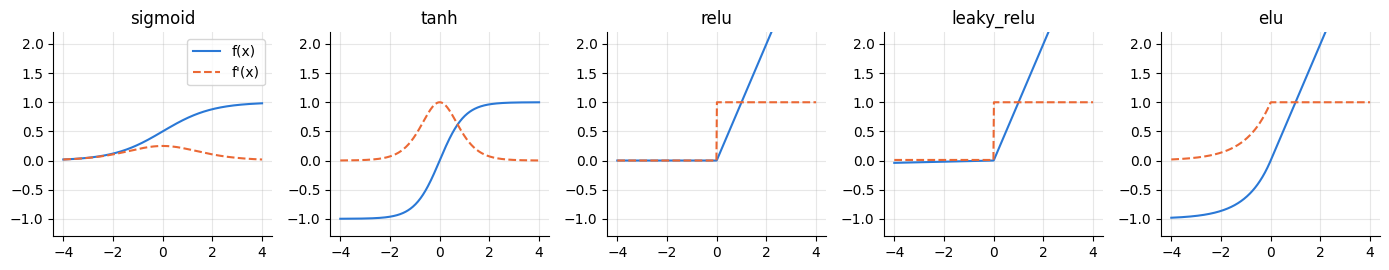

In [5]:
x = np.linspace(-4, 4, 400)
fig, axs = plt.subplots(1, 5, figsize=(14, 2.8))
for ax, (name, (f, df, _)) in zip(axs, pairs.items()):
    ax.plot(x, f(x), color=C[0], label="f(x)"); ax.plot(x, df(x), "--", color=C[1], label="f'(x)")
    ax.set_title(name); ax.set_ylim(-1.3, 2.2)
axs[0].legend(); plt.tight_layout(); plt.show()

## 5. Experiment: vanishing gradients in a deep network
Build a 20-layer MLP with each activation. Push one batch through, backprop, and compare the gradient size at the **first** layer with the **last** layer.
We run it twice: (a) with PyTorch's default `nn.Linear` initialization, and (b) with the initialization each activation was designed for (Xavier/Glorot for sigmoid/tanh, He/Kaiming for the ReLU family).

In [6]:
def grad_ratio(act, init=None, depth=20, width=64, seed=0):
    torch.manual_seed(seed)
    layers = []
    for _ in range(depth):
        lin = nn.Linear(width, width)
        if init is not None:
            init(lin.weight); nn.init.zeros_(lin.bias)
        layers += [lin, act()]
    net = nn.Sequential(*layers, nn.Linear(width, 1))
    x = torch.randn(256, width)
    net(x).pow(2).mean().backward()
    return net[0].weight.grad.norm().item(), net[-1].weight.grad.norm().item()

xavier      = lambda w: nn.init.xavier_normal_(w)
xavier_tanh = lambda w: nn.init.xavier_normal_(w, gain=nn.init.calculate_gain("tanh"))
he          = lambda w: nn.init.kaiming_normal_(w, nonlinearity="relu")
he_leaky    = lambda w: nn.init.kaiming_normal_(w, a=0.01, nonlinearity="leaky_relu")
cases = [("Sigmoid", nn.Sigmoid, xavier), ("Tanh", nn.Tanh, xavier_tanh), ("ReLU", nn.ReLU, he),
         ("LeakyReLU", nn.LeakyReLU, he_leaky), ("ELU", nn.ELU, he)]

print(f"{'activation':11s} {'ratio |grad L1| / |grad last|':>32s}")
print(f"{'':11s} {'(a) default init':>16s} {'(b) matched init':>16s}")
for name, act, init in cases:
    fa, la = grad_ratio(act); fb, lb = grad_ratio(act, init)
    print(f"{name:11s} {fa/la:16.1e} {fb/lb:16.1e}")

activation     ratio |grad L1| / |grad last|
            (a) default init (b) matched init
Sigmoid              1.2e-18          2.7e-14
Tanh                 1.1e-05          3.6e-01
ReLU                 3.6e-08          7.8e-02
LeakyReLU            3.8e-08          8.4e-02
ELU                  7.0e-06          1.5e-01


Reading the table:
* **Sigmoid** vanishes catastrophically (around $10^{-14}$ or smaller) **even with its matched Xavier init**. That's the $\sigma' \le 0.25$ effect compounding over 20 layers, and why sigmoid isn't used in deep hidden layers.
* With the **right initialization**, tanh and the ReLU family keep the first-layer gradient within about one order of magnitude of the last layer's.
* With default init, even ReLU shrinks a lot over 20 layers. Initialization and activation have to be chosen together, which is why He init exists.

## 6. Experiment: dying ReLU, and Leaky ReLU as the fix
We push a layer's biases strongly negative (similar to what a too-large update can do) and count units that output 0 for **every** example.

In [7]:
torch.manual_seed(0)
x = torch.randn(1000, 32)
lin = nn.Linear(32, 100)
with torch.no_grad():
    lin.bias.fill_(-3.0)                                   # simulate a bad update
for name, act in [("ReLU", nn.ReLU()), ("LeakyReLU(0.01)", nn.LeakyReLU(0.01))]:
    lin.zero_grad()
    out = act(lin(x))
    out.sum().backward()
    dead = (out <= 0).all(dim=0).float().mean().item()        # never positive for any example
    zero_grad_units = (lin.weight.grad.abs().sum(dim=1) == 0).float().mean().item()
    print(f"{name:16s} units never active: {dead:5.0%} | units with exactly zero gradient: {zero_grad_units:5.0%}")

ReLU             units never active:  100% | units with exactly zero gradient:  100%
LeakyReLU(0.01)  units never active:  100% | units with exactly zero gradient:    0%


With ReLU, most units never fire and get **exactly zero gradient**, so they can't recover. With Leaky ReLU they're still inactive, but every unit keeps a small gradient and can move back.

## 7. Softmax: numerical stability and the "double softmax" bug

In [8]:
z = np.array([1000.0, 999.0, 998.0])
with np.errstate(over="ignore", invalid="ignore"):
    naive = np.exp(z) / np.exp(z).sum()
print("naive softmax :", naive)                  # nan: exp(1000) overflows
print("stable softmax:", softmax(z).round(4))    # subtract max first
print("softmax(1,1,1) =", softmax(np.ones(3)), " softmax(101,101,101) =", softmax(np.full(3, 101.)))

naive softmax : [nan nan nan]
stable softmax: [0.6652 0.2447 0.09  ]
softmax(1,1,1) = [0.33333333 0.33333333 0.33333333]  softmax(101,101,101) = [0.33333333 0.33333333 0.33333333]


In [9]:
# CrossEntropyLoss already applies log-softmax. Feeding it softmax outputs applies softmax twice.
logits = torch.tensor([[4.0, 0.0, -2.0]], requires_grad=True)
target = torch.tensor([2])                         # the model is confidently WRONG
ce = nn.CrossEntropyLoss()

loss_ok = ce(logits, target); loss_ok.backward()
g_ok = logits.grad.clone(); logits.grad = None
loss_bug = ce(torch.softmax(logits, -1), target); loss_bug.backward()
g_bug = logits.grad.clone()
print(f"correct : loss={loss_ok.item():.3f}  grad={g_ok.numpy().round(3)}")
print(f"bug     : loss={loss_bug.item():.3f}  grad={g_bug.numpy().round(3)}   <- much weaker signal")

correct : loss=6.021  grad=[[ 0.98   0.018 -0.998]]
bug     : loss=1.542  grad=[[ 0.009 -0.006 -0.003]]   <- much weaker signal


## 8. scikit-learn: activations available in `MLPClassifier`
scikit-learn offers only `identity`, `logistic`, `tanh` and `relu`. With `identity` the network is linear and **cannot** solve a non-linear problem (the XOR-like "moons"); it matches logistic regression. `logistic` hidden units may also stay near that level here: sigmoid networks train slowly, as the vanishing-gradient experiment above suggests. `tanh` and `relu` learn the curved boundary.

In [10]:
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
import warnings; warnings.filterwarnings("ignore")

X, y = make_moons(n_samples=1000, noise=0.2, random_state=0)
Xtr, Xte, ytr, yte = train_test_split(X, y, random_state=0)
for act in ["identity", "logistic", "tanh", "relu"]:
    clf = MLPClassifier(hidden_layer_sizes=(32, 32), activation=act, max_iter=2000, random_state=0).fit(Xtr, ytr)
    print(f"{act:9s} test accuracy = {clf.score(Xte, yte):.3f}   output activation: {clf.out_activation_}")

identity  test accuracy = 0.832   output activation: logistic


logistic  test accuracy = 0.832   output activation: logistic


tanh      test accuracy = 0.952   output activation: logistic


relu      test accuracy = 0.964   output activation: logistic


## 9. Where these go in a PyTorch model (pattern)
Hidden layers get an activation; the output layer has **none**, because the loss applies sigmoid/softmax internally. At inference you apply sigmoid/softmax yourself.

In [11]:
class Classifier(nn.Module):
    def __init__(self, d_in, n_classes):
        super().__init__()
        self.body = nn.Sequential(nn.Linear(d_in, 64), nn.ReLU(), nn.Linear(64, 64), nn.ReLU())
        self.head = nn.Linear(64, n_classes)        # raw logits, no softmax here
    def forward(self, x):
        return self.head(self.body(x))

m = Classifier(2, 3)
logits = m(torch.randn(4, 2))
print("logits shape:", tuple(logits.shape))
print("loss (train):", nn.CrossEntropyLoss()(logits, torch.tensor([0, 1, 2, 0])).item())
print("probs (inference):", torch.softmax(logits, dim=-1).detach().numpy().round(3))

logits shape: (4, 3)
loss (train): 1.0512652397155762
probs (inference): [[0.348 0.298 0.354]
 [0.302 0.409 0.289]
 [0.316 0.373 0.311]
 [0.337 0.318 0.346]]
